# Claim function × proposition kind evaluation (taxonomy v0.9)

**Goal:** test the two-axis ontology on the first 4 samples with haiku and opus.

| Axis | Values | Shown in diagrams as |
|---|---|---|
| Claim function (*how* the claim is made) | RECOMMENDATION, PREDICTION, ASSESSMENT, OBSERVATION | node colour |
| Proposition kind (*what* it is about) | investment_action (ACT), causal_relationship (CAUSE), valuation (VAL), positioning (POS), sentiment (SENT), event (EVT), market_state (MS) | `[ABBR]` marker, `[ABBR·SCn]` inside a scenario |
| Scenario (hypothetical context) | role, outcome_orientation, purpose; assumptions → outcomes → recommendations | marker suffix |

**Pipeline** (repo root):

```
.venv\Scripts\python.exe scripts\run_samples.py --limit 4
```

The setup cell rebuilds `claims_analysis/claims_all.csv` whenever the set of valid maps changes (for example after a failed run is retried), and clears the alignment caches.

**Questions:**

1. Do haiku and opus agree on function and kind, and is agreement higher than with the 9 v0.8 types?
2. Where did each v0.8 type go?
3. Are the function boundaries (ASSESSMENT vs PREDICTION, ASSESSMENT vs OBSERVATION) applied consistently?
4. Are the kinds distinctive, and are numbers now attributes rather than types?
5. How are scenarios and attribution used?

Probes are regex heuristics, not extractions.

## 0. Setup

In [ ]:
import json
import sys
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from incolor.argumentation.evaluate import match_statements
from incolor.argumentation.writer import load_argument_map

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RUNS_DIR = ROOT / "outputs" / "samples_v09"
DATA_DIR = RUNS_DIR / "claims_analysis"
V08_DIR = ROOT / "outputs" / "samples_v08"
FUNCTIONS = ["RECOMMENDATION", "PREDICTION", "ASSESSMENT", "OBSERVATION"]
KINDS = ["investment_action", "causal_relationship", "valuation", "positioning", "sentiment", "event", "market_state"]
ABBREV = {
    "investment_action": "ACT", "causal_relationship": "CAUSE", "valuation": "VAL", "positioning": "POS",
    "sentiment": "SENT", "event": "EVT", "market_state": "MS",
}
V08_TYPES = [
    "RECOMMENDATION", "VALUATION", "FORECAST", "PREDICTION", "POSITIONING", "SENTIMENT", "VIEW", "DATA_POINT",
    "OBSERVATION",
]
MODELS = ["haiku", "opus"]
PIVOT_MODEL = "opus"
JSON_COLUMNS = ["evidence_ids", "evidence_texts", "roles", "argument_ids"]
CACHES = ["pairwise.csv", "v08_alignment.csv"]

# Rebuild the CSV when the set of valid maps has changed; the alignment caches depend on it.
claims_path = DATA_DIR / "claims_all.csv"
valid_maps = {p.relative_to(ROOT).as_posix() for p in RUNS_DIR.glob("*/*/argument_map.yaml")}
built_maps = (
    set(pd.read_csv(claims_path, usecols=["map_path"], encoding="utf-8-sig")["map_path"])
    if claims_path.exists()
    else set()
)
if built_maps != valid_maps:
    sys.path.insert(0, str(ROOT / "scripts"))
    import build_claims_csv

    build_claims_csv.main([
        "--runs-root", str(RUNS_DIR), "--texts-dir", str(RUNS_DIR / "inputs"), "--no-gold",
        "--pivot-model", PIVOT_MODEL, "--out", str(DATA_DIR),
    ])
    for name in CACHES:
        (DATA_DIR / name).unlink(missing_ok=True)

claims = pd.read_csv(claims_path, encoding="utf-8-sig")
for col in JSON_COLUMNS:
    claims[col] = claims[col].map(lambda v: json.loads(v) if isinstance(v, str) and v else [])
DOCS = sorted(claims["doc"].unique())
LABEL = {doc: doc.split("_-_")[0].replace("__", " ").replace("_", " ")[:24] for doc in DOCS}
claims["label"] = claims["doc"].map(LABEL)
claims["kind"] = claims["proposition_kind"].map(ABBREV)

pd.set_option("display.max_colwidth", 160)
pd.set_option("display.max_rows", 200)
print(f"{len(claims)} statements from {claims['run_id'].nunique()} runs over {len(DOCS)} samples")
pd.crosstab(claims["label"], claims["model"]).reindex(columns=MODELS, fill_value=0)

618 statements from 7 runs over 4 samples


model,haiku,opus
label,,
BC FX Views,0,120
Beam yields up Scotty,112,124
BofA Liquid Insight,44,45
BofA Sept FOMC,63,110


In [25]:
SHOW = ["label", "model", "statement_id", "claim_type", "kind", "modality", "attribution", "statement"]


def probe(df, patterns, col="statement"):
    """One boolean column per named regex (case-insensitive) matched against ``col``."""
    return pd.DataFrame(
        {name: df[col].str.contains(p, case=False, regex=True, na=False) for name, p in patterns.items()},
        index=df.index,
    )


def fill_rates(df, patterns, by="claim_type", col="statement"):
    """Share of rows matching each probe, per group (probes as rows)."""
    return probe(df, patterns, col).groupby(df[by]).mean().round(2).T


def heatmap(table, title, xlabel, ylabel, ax=None):
    """Row-normalised heat map of a count table, annotated with the counts."""
    if ax is None:
        _, ax = plt.subplots(figsize=(1.5 + 0.9 * table.shape[1], 1 + 0.55 * table.shape[0]))
    shares = table.div(table.sum(axis=1).replace(0, 1), axis=0)
    ax.imshow(shares, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(table.shape[1]), table.columns, rotation=45, ha="right")
    ax.set_yticks(range(table.shape[0]), table.index)
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            if table.iat[i, j]:
                ax.text(j, i, table.iat[i, j], ha="center", va="center", fontsize=8)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    return ax


# One row per (statement, argument, role).
memberships = claims[["run_id", "model", "doc", "statement_id", "claim_type", "kind", "roles"]].explode("roles")
memberships = memberships.dropna(subset=["roles"]).reset_index(drop=True)
memberships["role"] = memberships["roles"].map(lambda r: r["role"])
memberships = memberships.drop(columns="roles")

## 1. Runs: success, cost and structure, against v0.8

In [26]:
def load_runs(runs_dir):
    runs = pd.DataFrame([json.loads(p.read_text(encoding="utf-8")) for p in sorted(runs_dir.glob("*/*/summary.json"))])
    runs["label"] = runs["doc"].map(lambda d: LABEL.get(d, d[:24]))
    runs["stmts_per_1k"] = runs["statements"] / runs["src_chars"] * 1000
    return runs


runs = load_runs(RUNS_DIR)
RUN_COLS = [
    "label", "model", "ok", "attempts", "seconds", "cost_usd", "arguments", "statements", "scenarios", "edges",
    "isolated", "exclusions",
]
failed = runs[~runs["ok"].fillna(False).astype(bool)]
print(f"{len(runs)} runs, {len(failed)} without a valid map")
if len(failed):
    display(failed.reindex(columns=["label", "model", "attempts", "errors", "issue_codes", "error"]))
runs.reindex(columns=RUN_COLS).sort_values(["label", "model"])

8 runs, 1 without a valid map


,label,model,attempts,errors,issue_codes,error
0,BC FX Views,haiku,3,3,"{'EVIDENCE_NOT_VERBATIM': 1, 'CUE_NOT_IN_EVIDENCE': 2}",NaN


,label,model,ok,attempts,seconds,cost_usd,arguments,statements,scenarios,edges,isolated,exclusions
0,BC FX Views,haiku,False,3,747.3,0.3274,19,108,0,19,1,6
1,BC FX Views,opus,True,2,750.4,2.6451,22,120,1,19,2,7
2,Beam yields up Scotty,haiku,True,1,395.5,0.0612,25,112,0,6,14,22
3,Beam yields up Scotty,opus,True,2,667.0,2.2503,27,124,0,16,10,21
4,BofA Liquid Insight,haiku,True,2,328.2,0.0563,11,44,1,6,3,6
5,BofA Liquid Insight,opus,True,1,207.4,0.7042,11,45,1,8,0,4
6,BofA Sept FOMC,haiku,True,2,744.6,0.1176,19,63,3,7,9,14
7,BofA Sept FOMC,opus,True,2,654.1,2.2292,28,110,4,22,7,8


In [27]:
# The same samples and models under v0.8, for structure and cost.
AGG = dict(
    runs=("doc", "size"), valid=("ok", "sum"), cost_usd=("cost_usd", "sum"), mean_attempts=("attempts", "mean"),
    median_seconds=("seconds", "median"), median_stmts=("statements", "median"),
    median_stmts_per_1k=("stmts_per_1k", "median"), median_args=("arguments", "median"),
    median_edges=("edges", "median"), median_exclusions=("exclusions", "median"),
)
v08_runs = load_runs(V08_DIR)
compare = pd.concat(
    {
        "v0.8": v08_runs[v08_runs["model"].isin(MODELS)].groupby("model").agg(**AGG),
        "v0.9": runs.groupby("model").agg(**AGG),
    },
    names=["taxonomy"],
).round(2)
display(compare)
# Issue codes from the final attempt of each run.
pd.DataFrame(runs.set_index("model")["issue_codes"].dropna().apply(pd.Series)).groupby(level=0).sum().T

runs  valid  cost_usd  mean_attempts  median_seconds  \
taxonomy model                                                         
v0.8     haiku     4      3      0.36           2.00          438.75   
         opus      4      4      6.51           1.50          557.65   
v0.9     haiku     4      3      0.56           2.00          570.05   
         opus      4      4      7.83           1.75          660.55   

                median_stmts  median_stmts_per_1k  median_args  median_edges  \
taxonomy model                                                                 
v0.8     haiku          81.0                 3.57         22.0          11.5   
         opus          112.5                 4.95         24.5          15.5   
v0.9     haiku          85.5                 3.52         19.0           6.5   
         opus          115.0                 4.97         24.5          17.5   

                median_exclusions  
taxonomy model                     
v0.8     haiku               19.5  
         opus                10.0  
v0.9     haiku               10.0  
         opus                 7.5

model,haiku,opus
EVIDENCE_NOT_VERBATIM,1.0,0.0
CUE_NOT_IN_EVIDENCE,2.0,0.0
EXCLUSION_NOT_VERBATIM,2.0,0.0
BRIEF_TOO_LONG,2.0,0.0


### Observations

| Median per run | v0.8 haiku | v0.9 haiku | v0.8 opus | v0.9 opus |
|---|---|---|---|---|
| Valid runs | 3/4 | 3/4 | 4/4 | 4/4 |
| Total cost | $0.36 | $0.56 | $6.51 | $7.83 |
| Statements | 81 | 85.5 | 112.5 | 115 |
| Edges | 11.5 | 6.5 | 15.5 | 17.5 |
| Exclusions | 19.5 | 10 | 10 | 7.5 |

- The map structure is essentially unchanged. Opus costs about 20% more under v0.9, from a longer prompt and two extra fields per statement.
- **BC FX haiku is the only failure.** It failed after 3 attempts on 1 `EVIDENCE_NOT_VERBATIM` and 2 `CUE_NOT_IN_EVIDENCE` issues. That is its third failure on this document across v0.8 and v0.9, so the document is treated as **opus-only**. The failures are errors in copying quotes verbatim, not taxonomy errors.
- Haiku links statements less under v0.9: median edges fall from 11.5 to 6.5, and Beam has 14 isolated statements.


## 2. Side-by-side model maps

`outputs/samples_v09/<doc>/models_list.mmd` shows haiku and opus as two columns in list view, observations included. Colour = claim function (RECOMMENDATION red, PREDICTION yellow, ASSESSMENT blue, OBSERVATION grey); the bracketed marker = proposition kind, with `·SCn` when the statement belongs to scenario *n*.

In [28]:
# The diagrams are too large for the mermaid.ink render API (HTTP 414); open the .mmd files in VS Code instead.
for path in sorted(RUNS_DIR.glob("*/models_list.mmd")):
    print(path.relative_to(ROOT).as_posix())

outputs/samples_v09/BC_FX_Views_-_Structural_JPY_weakness_unchanged/models_list.mmd
outputs/samples_v09/Beam_yields_up__Scotty/models_list.mmd
outputs/samples_v09/BofA_Liquid_Insight_-_France_risks_for_EUR/models_list.mmd
outputs/samples_v09/BofA_Sept_FOMC_-_hike_or_bond_spike/models_list.mmd


## 3. Function × kind grid

Is each axis used independently? A useful second axis spreads across functions rather than duplicating them.

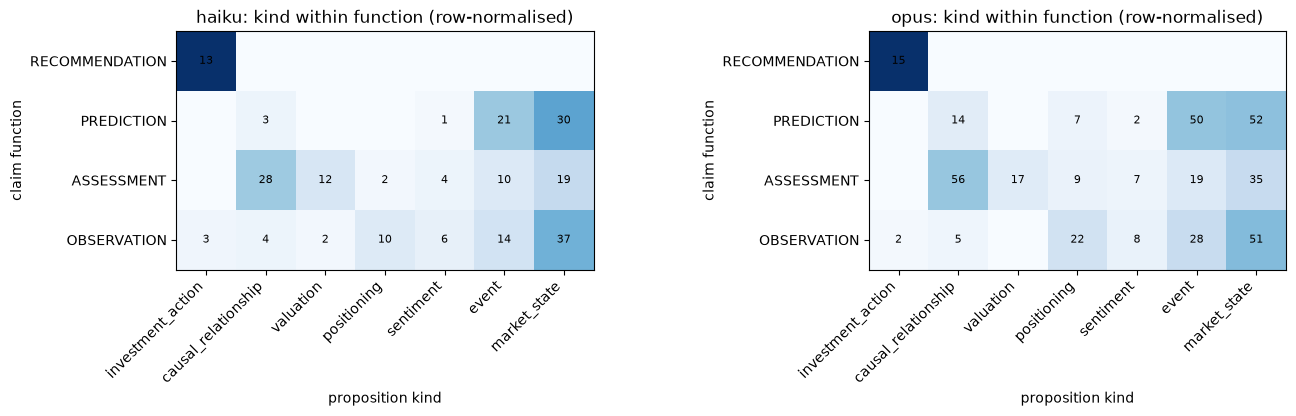

proposition_kind,investment_action,causal_relationship,valuation,positioning,sentiment,event,market_state,total
claim_type,,,,,,,,
RECOMMENDATION,28,0,0,0,0,0,0,28
PREDICTION,0,17,0,7,3,71,82,180
ASSESSMENT,0,84,29,11,11,29,54,218
OBSERVATION,5,9,2,32,14,42,88,192


In [29]:
grid = pd.crosstab(claims["claim_type"], claims["proposition_kind"]).reindex(index=FUNCTIONS, columns=KINDS, fill_value=0)
fig, axes = plt.subplots(1, len(MODELS), figsize=(14, 4))
for ax, model in zip(axes, MODELS, strict=True):
    sub = claims[claims["model"] == model]
    table = pd.crosstab(sub["claim_type"], sub["proposition_kind"]).reindex(index=FUNCTIONS, columns=KINDS, fill_value=0)
    heatmap(table, f"{model}: kind within function (row-normalised)", "proposition kind", "claim function", ax=ax)
plt.tight_layout()
plt.show()
grid.assign(total=grid.sum(axis=1))

In [30]:
display(
    pd.crosstab(claims["model"], claims["claim_type"], normalize="index").round(2)
    .reindex(index=MODELS, columns=FUNCTIONS, fill_value=0)
)
display(
    pd.crosstab(claims["model"], claims["proposition_kind"], normalize="index").round(2)
    .reindex(index=MODELS, columns=KINDS, fill_value=0)
)
# Kind mix per sample (both models pooled): which documents drive each kind?
pd.crosstab(claims["label"], claims["proposition_kind"], normalize="index").round(2).reindex(columns=KINDS, fill_value=0)

claim_type,RECOMMENDATION,PREDICTION,ASSESSMENT,OBSERVATION
model,,,,
haiku,0.06,0.25,0.34,0.35
opus,0.04,0.31,0.36,0.29


proposition_kind,investment_action,causal_relationship,valuation,positioning,sentiment,event,market_state
model,,,,,,,
haiku,0.07,0.16,0.06,0.05,0.05,0.21,0.39
opus,0.04,0.19,0.04,0.10,0.04,0.24,0.35


proposition_kind,investment_action,causal_relationship,valuation,positioning,sentiment,event,market_state
label,,,,,,,
BC FX Views,0.00,0.22,0.03,0.23,0.02,0.18,0.32
Beam yields up Scotty,0.13,0.12,0.06,0.07,0.04,0.18,0.41
BofA Liquid Insight,0.03,0.24,0.15,0.06,0.11,0.25,0.17
BofA Sept FOMC,0.00,0.20,0.01,0.00,0.03,0.32,0.43


In [31]:
# One example per function × kind cell, opus first.
examples = (
    claims.sort_values("model", key=lambda s: s.map({"opus": 0, "haiku": 1}))
    .groupby(["claim_type", "proposition_kind"])
    .head(1)
)
examples.set_index(["claim_type", "proposition_kind"]).sort_index()[["label", "model", "statement"]]

label  model  \
claim_type     proposition_kind                                    
ASSESSMENT     causal_relationship            BC FX Views   opus   
               event                          BC FX Views   opus   
               market_state                   BC FX Views   opus   
               positioning                    BC FX Views   opus   
               sentiment                      BC FX Views   opus   
               valuation                      BC FX Views   opus   
OBSERVATION    causal_relationship    BofA Liquid Insight   opus   
               event                       BofA Sept FOMC   opus   
               investment_action    Beam yields up Scotty   opus   
               market_state                   BC FX Views   opus   
               positioning                    BC FX Views   opus   
               sentiment                      BC FX Views   opus   
               valuation              BofA Liquid Insight  haiku   
PREDICTION     causal_relationship            BC FX Views   opus   
               event                          BC FX Views   opus   
               market_state                   BC FX Views   opus   
               positioning                    BC FX Views   opus   
               sentiment                   BofA Sept FOMC   opus   
RECOMMENDATION investment_action      BofA Liquid Insight   opus   

                                                                                                                                                                                          statement  
claim_type     proposition_kind                                                                                                                                                                      
ASSESSMENT     causal_relationship                                     Expanding inward direct investment is only partially offsetting the JPY selling pressure from outward FDI and corporate M&A.  
               event                                               The US part of the intervention was likely funded from the ESF's foreign-currency holdings (a combined USD4.4bn in JPY and EUR).  
               market_state                                                                                                                    Corporate revenue flow is biased toward JPY selling.  
               positioning                                                                                               Households' JPY-selling activity remains intact and has not receded in H2.  
               sentiment                                                                          Concerns over the Takaichi administration's 'high-pressure economy policy' remain a JPY headwind.  
               valuation                                                        Even without political pressure, current yen rate levels could justify some GPIF shift back toward domestic assets.  
OBSERVATION    causal_relationship                       For sufficiently large shocks, a 10bp widening in the OAT-Bund spread has historically been associated with a roughly 0.4% weaker EUR-USD.  
               event                Since July the market has received mixed USD signals: Warsh's Jackson Hole course correction and a strong August labour report, versus dovish Williams and W...  
               investment_action                                                                                                             The Boost model now uses CHF to fund all of its ideas.  
               market_state         Hawkish remarks by BoJ officials including Board Member Takata pushed market pricing for BoJ hikes by year-end from around 40bp in August to 45-50bp in Sept...  
               positioning                                                                                                           Japanese companies remain active in outward direct investment.  
               sentiment                  The GPI

### Observations

| Function | n | Share | Main kinds |
|---|---|---|---|
| RECOMMENDATION | 28 | 5% | ACT 100% (by rule) |
| PREDICTION | 180 | 29% | MS 82, EVT 71, CAUSE 17 |
| ASSESSMENT | 218 | 35% | CAUSE 84, MS 54, VAL 29, EVT 29 |
| OBSERVATION | 192 | 31% | MS 88, EVT 42, POS 32 |

- **The two axes are independent.** Every function except RECOMMENDATION covers 6–7 kinds.
- The characteristic cells match the design: valuation sits in ASSESSMENT·VAL, flows in OBSERVATION·POS, and mechanisms in ASSESSMENT·CAUSE.
- market_state (36%) and event (23%) dominate. valuation, sentiment and positioning are each 8% or less.
- **Unexpected cells:**
  - OBSERVATION·ACT (5): trading-model holdings reported as facts (see §9).
  - ASSESSMENT·EVT: inferred past events, such as "the intervention was likely funded from the ESF".
- Haiku and opus have the same function mix, within ±6pp. Opus uses positioning more (10% vs 5%), mostly on BC FX, where haiku has no map.


## 4. Model invariance: haiku vs opus

Pairwise agreement on matched statements, compared with the v0.8 haiku–opus type agreement on the same samples.

In [32]:
# Matching is slow (difflib), so results are cached; the setup cell clears the cache when the maps change.
pairwise_path = DATA_DIR / "pairwise.csv"
if pairwise_path.exists():
    pairwise = pd.read_csv(pairwise_path, encoding="utf-8-sig")
else:
    rows = []
    for doc in DOCS:
        maps = {m: load_argument_map(p) for m in MODELS if (p := RUNS_DIR / doc / m / "argument_map.yaml").exists()}
        for a, b in combinations([m for m in MODELS if m in maps], 2):
            mapping = match_statements(maps[a], maps[b])
            sa, sb = {s.id: s for s in maps[a].statements}, {s.id: s for s in maps[b].statements}
            pairs_ = [(sa[x], sb[y]) for x, y in mapping.items()]
            n = len(pairs_)

            def share(test, pairs_=pairs_, n=n):
                return sum(test(x, y) for x, y in pairs_) / n if n else None

            rows.append({
                "doc": doc,
                "pair": f"{a}-{b}",
                "matched": n,
                "stmt_overlap_f1": 2 * n / (len(sa) + len(sb)),
                "function_agreement": share(lambda x, y: x.claim_type == y.claim_type),
                "kind_agreement": share(lambda x, y: x.proposition_kind == y.proposition_kind),
                "joint_agreement": share(
                    lambda x, y: x.claim_type == y.claim_type and x.proposition_kind == y.proposition_kind
                ),
                "modality_agreement": share(lambda x, y: x.modality == y.modality),
            })
    pairwise = pd.DataFrame(rows)
    pairwise.to_csv(pairwise_path, index=False, encoding="utf-8-sig")
pairwise["label"] = pairwise["doc"].map(LABEL)

v08_pairwise = pd.read_csv(V08_DIR / "claims_analysis" / "pairwise.csv", encoding="utf-8-sig")
v08_pairwise = v08_pairwise[v08_pairwise["pair"] == "haiku-opus"].assign(label=lambda d: d["doc"].map(LABEL))
AGREEMENT = ["matched", "stmt_overlap_f1", "function_agreement", "kind_agreement", "joint_agreement", "modality_agreement"]
display(pairwise.set_index("label")[AGREEMENT].round(2))
pd.DataFrame({
    "v0.8 type (9)": v08_pairwise.set_index("label")["type_agreement"],
    "v0.9 function (4)": pairwise.set_index("label")["function_agreement"],
    "v0.9 kind (7)": pairwise.set_index("label")["kind_agreement"],
    "v0.9 function + kind": pairwise.set_index("label")["joint_agreement"],
}).round(2)

,matched,stmt_overlap_f1,function_agreement,kind_agreement,joint_agreement,modality_agreement
label,,,,,,
Beam yields up Scotty,84,0.71,0.96,0.93,0.90,0.98
BofA Liquid Insight,37,0.83,0.92,0.84,0.81,0.81
BofA Sept FOMC,47,0.54,0.91,0.74,0.72,0.87


,v0.8 type (9),v0.9 function (4),v0.9 kind (7),v0.9 function + kind
label,,,,
Beam yields up Scotty,0.84,0.96,0.93,0.90
BofA Liquid Insight,0.86,0.92,0.84,0.81
BofA Sept FOMC,0.86,0.91,0.74,0.72


In [33]:
# Agreement with the opus pivot of each statement cluster, by the pivot's function and kind.
aligned = claims.dropna(subset=["cluster_id"])
aligned = aligned[aligned["run_id"] != aligned["cluster_pivot"]].copy()
aligned["function_ok"] = aligned["claim_type"] == aligned["cluster_pivot_claim_type"]
aligned["kind_ok"] = aligned["proposition_kind"] == aligned["cluster_pivot_proposition_kind"]
print(f"{len(aligned)} haiku statements aligned to an opus statement")
display(aligned.groupby("cluster_pivot_claim_type")["function_ok"].agg(["mean", "size"]).reindex(FUNCTIONS).round(2))
aligned.groupby("cluster_pivot_proposition_kind")["kind_ok"].agg(["mean", "size"]).reindex(KINDS).round(2)

168 haiku statements aligned to an opus statement


,mean,size
cluster_pivot_claim_type,,
RECOMMENDATION,0.83,6
PREDICTION,0.98,42
ASSESSMENT,0.89,66
OBSERVATION,0.98,54


,mean,size
cluster_pivot_proposition_kind,,
investment_action,0.88,8
causal_relationship,0.78,36
valuation,0.82,11
positioning,0.86,7
sentiment,0.89,9
event,0.83,35
market_state,0.92,62


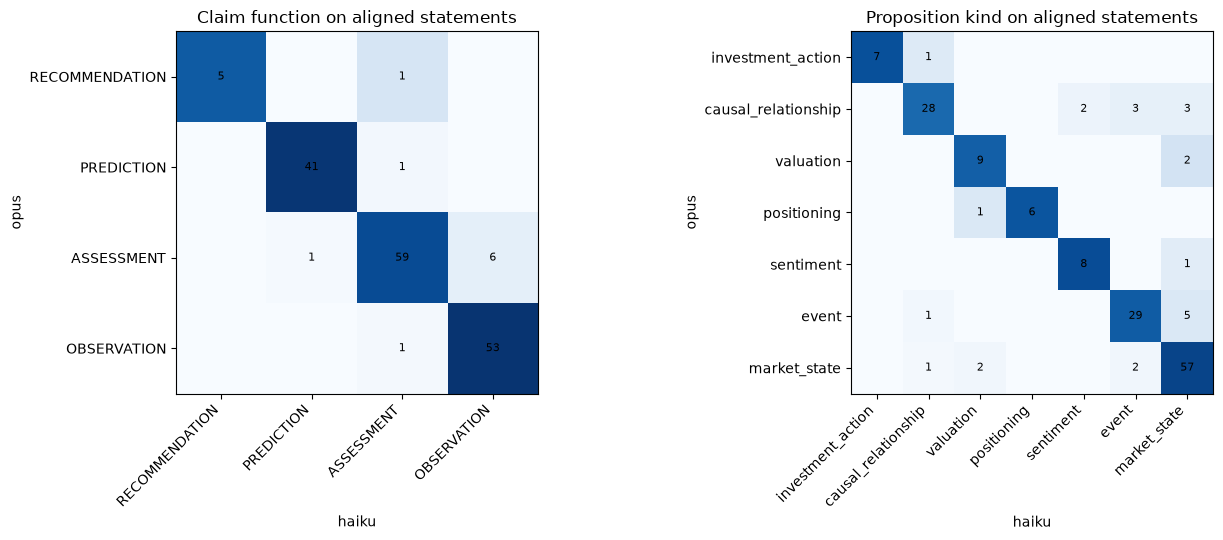

,rows,docs
ASSESSMENT -> OBSERVATION,6,3
ASSESSMENT -> PREDICTION,1,1
OBSERVATION -> ASSESSMENT,1,1
PREDICTION -> ASSESSMENT,1,1
RECOMMENDATION -> ASSESSMENT,1,1


,rows,docs
causal_relationship -> event,3,1
causal_relationship -> market_state,3,2
causal_relationship -> sentiment,2,1
event -> causal_relationship,1,1
event -> market_state,5,2
investment_action -> causal_relationship,1,1
market_state -> causal_relationship,1,1
market_state -> event,2,2
market_state -> valuation,2,1
positioning -> valuation,1,1


In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
function_confusion = pd.crosstab(aligned["cluster_pivot_claim_type"], aligned["claim_type"]).reindex(
    index=FUNCTIONS, columns=FUNCTIONS, fill_value=0
)
kind_confusion = pd.crosstab(aligned["cluster_pivot_proposition_kind"], aligned["proposition_kind"]).reindex(
    index=KINDS, columns=KINDS, fill_value=0
)
heatmap(function_confusion, "Claim function on aligned statements", "haiku", "opus", ax=axes[0])
heatmap(kind_confusion, "Proposition kind on aligned statements", "haiku", "opus", ax=axes[1])
plt.tight_layout()
plt.show()


def disagreements(pivot_col, col):
    off = aligned[aligned[col] != aligned[pivot_col]]
    pair = off[pivot_col].astype(str) + " -> " + off[col].astype(str)
    return pd.DataFrame({"rows": pair.value_counts(), "docs": off.groupby(pair)["doc"].nunique()})


display(disagreements("cluster_pivot_claim_type", "claim_type"))
disagreements("cluster_pivot_proposition_kind", "proposition_kind")

In [35]:
pivot_rows = claims[claims["run_id"] == claims["cluster_pivot"]].set_index("cluster_id")


def side_by_side(mask):
    """Aligned haiku statements selected by ``mask`` next to their opus counterparts."""
    rows = aligned[mask]
    pivot = pivot_rows.loc[rows["cluster_id"]]
    return pd.DataFrame({
        "label": rows["label"].to_numpy(),
        "opus": (pivot["claim_type"] + " · " + pivot["kind"].fillna("?")).to_numpy(),
        "haiku": (rows["claim_type"] + " · " + rows["kind"].fillna("?")).to_numpy(),
        "opus statement": pivot["statement"].to_numpy(),
        "haiku statement": rows["statement"].to_numpy(),
    })


print("Function disagreements")
display(side_by_side(~aligned["function_ok"]))
print("Same function, different kind")
side_by_side(aligned["function_ok"] & ~aligned["kind_ok"])

Function disagreements


,label,opus,haiku,opus statement,haiku statement
0,Beam yields up Scotty,ASSESSMENT · EVT,OBSERVATION · EVT,The BoJ has shifted to a more hawkish tone.,The BoJ has shifted more hawkish in tone.
1,Beam yields up Scotty,ASSESSMENT · MS,OBSERVATION · EVT,The SNB is the most dovish G10 central bank.,The SNB is the most dovish central bank.
2,Beam yields up Scotty,ASSESSMENT · SENT,OBSERVATION · SENT,Investor risk appetite is positive.,Risk appetite is positive.
3,BofA Liquid Insight,ASSESSMENT · EVT,OBSERVATION · EVT,Limited polling available so far points to a potentially more competitive French presidential race than in previous instances.,Limited polling available so far points to a potentially more competitive race than in previous instances.
4,BofA Liquid Insight,OBSERVATION · POS,ASSESSMENT · VAL,Relative France vs Euro area equity inflows are consistent with the underperformance of French equities.,French equity underperformance is consistent with relative France versus euro area equity inflows.
5,BofA Liquid Insight,RECOMMENDATION · ACT,ASSESSMENT · CAUSE,"Investors should hedge France-related risks via CHF or GBP, which are cleaner expressions than EUR-USD.",CHF or GBP are cleaner expressions to hedge France-related risks than EUR-USD.
6,BofA Sept FOMC,ASSESSMENT · CAUSE,OBSERVATION · MS,The sharp shift in Fed pricing was catalysed by Warsh's Jackson Hole speech and stronger labour and inflation data.,The sharp shift in Fed pricing was catalyzed by Warsh's Jackson Hole speech and stronger labor and inflation data.
7,BofA Sept FOMC,ASSESSMENT · CAUSE,PREDICTION · MS,"If the Fed does not hike given current pricing, it risks a sharp and disorderly move in long-end UST yields.","If the Fed does not hike at current pricing, it risks a sharp and disorderly UST long-end move."
8,BofA Sept FOMC,PREDICTION · CAUSE,ASSESSMENT · CAUSE,"UST buybacks would prove futile to stop a long-end yield rise after a Fed hold, especially given their stumble out of the gate.",UST buybacks would be futile to stop a long-end selloff.
9,BofA Sept FOMC,ASSESSMENT · CAUSE,OBSERVATION · SENT,Dollar sentiment has soured since Warsh's July FOMC press conference raised credibility concerns over the lack of a plan to address above-target inflation.,Dollar sentiment has soured since Warsh's July FOMC press conference raised credibility concerns.


Same function, different kind


,label,opus,haiku,opus statement,haiku statement
0,Beam yields up Scotty,PREDICTION · EVT,PREDICTION · MS,The US Treasury is unlikely to accept $32bn worth of par in buyback offers.,Treasury is unlikely to accept $32bn worth of par offers in the buybacks.
1,Beam yields up Scotty,ASSESSMENT · EVT,ASSESSMENT · MS,The bar for the Fed to hike in September is relatively high.,The bar for the Fed to hike in September is relatively high.
2,Beam yields up Scotty,OBSERVATION · SENT,OBSERVATION · MS,The market already interprets the ECB as net hawkish.,The market already interprets the ECB as net hawkish.
3,Beam yields up Scotty,ASSESSMENT · CAUSE,ASSESSMENT · MS,The NOK is vulnerable to further declines in energy prices.,NOK is vulnerable to further declines in energy prices.
4,Beam yields up Scotty,ASSESSMENT · VAL,ASSESSMENT · MS,The CHF makes an ideal funding currency.,The CHF makes an ideal funder currency.
5,BofA Liquid Insight,OBSERVATION · MS,OBSERVATION · VAL,"BofA's simple proxy for France-related risks stands one standard deviation above its post-2015 average, its highest level since the 2017 presidential election.","A simple France-related risk proxy stands one standard deviation above its post-2015 average, the highest level since the 2017 presidential election."
6,BofA Liquid Insight,ASSESSMENT · MS,ASSESSMENT · CAUSE,Downside risks to the EUR continue to dominate over the medium term.,"France poses downside risks to the otherwise constructive medium-term EUR view, and these risks continue to dominate over the medium term."
7,BofA Liquid Insight,OBSERVATION · MS,OBSERVATION · VAL,Z-scores since 2015 show the steepness of the forward volatility curve in 6m3m space is 2 standard deviations above average for many EUR crosses.,The steepness of the 6m3m forward volatility premium curve is 2 standard deviations above average for many EUR crosses.
8,BofA Liquid Insight,PREDICTION · EVT,PREDICTION · CAUSE,France may prove more of a 2027 story than a late-2026 story for the EUR.,France may prove more of a 2027 story than a late-2026 story for the EUR.
9,BofA Sept FOMC,ASSESSMENT · CAUSE,ASSESSMENT · EVT,Friday's CPI data all but lock in a Fed rate hike this week.,Friday's CPI data all but locks in a rate hike at the September FOMC.


### Observations

| Sample | v0.8 type (9) | v0.9 function (4) | v0.9 kind (7) | v0.9 function + kind |
|---|---|---|---|---|
| Beam | 0.84 | **0.96** | 0.93 | 0.90 |
| BofA Liquid Insight | 0.86 | **0.92** | 0.84 | 0.81 |
| BofA Sept FOMC | 0.86 | **0.91** | 0.74 | 0.72 |

- **Function agreement beats v0.8 type agreement on every sample, by 5–12pp.** Function and kind together roughly match v0.8 on 2 samples and fall below it on FOMC.
- Function disagreements are 10 of 168 aligned statements:
  - 6 are opus ASSESSMENT vs haiku OBSERVATION. They involve short characterisations ("SNB is the most dovish G10 central bank", "Risk appetite is positive") and causal explanations of past moves ("Fed pricing shift was catalysed by…").
  - Haiku turned one recommendation ("hedge France risk via CHF or GBP") into an ASSESSMENT comparison.
- Kind agreement is lowest for **causal_relationship (0.78)** and **event (0.83)**, against 0.92 for market_state. The recurring confusions:

| Confusion | Typical statements |
|---|---|
| CAUSE vs MS / EVT / SENT | "X is vulnerable to Y", "bar to hike is high", "CPI data all but lock in a hike" |
| EVT vs MS | Fed dot-plot projections ("SEP median dot will show 50bp…"): opus EVT, haiku MS |
| MS vs VAL | z-scores and standard-deviation statements (haiku VAL) |

- Modality agreement is 0.81–0.98.


## 5. Where did the v0.8 types go?

Each v0.9 map is aligned to the v0.8 map of the same sample and model with the CSV's statement matcher, so every matched statement has a v0.8 type and a v0.9 function and kind.

In [36]:
mapping_path = DATA_DIR / "v08_alignment.csv"
if mapping_path.exists():
    v08_map = pd.read_csv(mapping_path, encoding="utf-8-sig")
else:
    rows = []
    for doc in DOCS:
        for model in MODELS:
            p09, p08 = RUNS_DIR / doc / model / "argument_map.yaml", V08_DIR / doc / model / "argument_map.yaml"
            if not (p09.exists() and p08.exists()):
                continue
            m09, m08 = load_argument_map(p09), load_argument_map(p08)
            old = {s.id: s for s in m08.statements}
            mapping = match_statements(m09, m08)
            for s in m09.statements:
                o = old.get(mapping.get(s.id))
                rows.append({
                    "doc": doc,
                    "model": model,
                    "statement_id": s.id,
                    "claim_type": s.claim_type,
                    "proposition_kind": s.proposition_kind,
                    "statement": s.statement,
                    "v08_statement_id": o.id if o else None,
                    "v08_type": o.claim_type if o else None,
                    "v08_statement": o.statement if o else None,
                })
    v08_map = pd.DataFrame(rows)
    v08_map.to_csv(mapping_path, index=False, encoding="utf-8-sig")
v08_map["label"] = v08_map["doc"].map(LABEL)
v08_map["kind"] = v08_map["proposition_kind"].map(ABBREV)
matched = v08_map.dropna(subset=["v08_type"])
print(f"{len(matched)}/{len(v08_map)} v0.9 statements matched a v0.8 statement")
pd.crosstab(matched["v08_type"], matched["claim_type"], margins=True).reindex(
    index=[*V08_TYPES, "All"], columns=[*FUNCTIONS, "All"], fill_value=0
)

523/618 v0.9 statements matched a v0.8 statement


claim_type,RECOMMENDATION,PREDICTION,ASSESSMENT,OBSERVATION,All
v08_type,,,,,
RECOMMENDATION,18,0,0,2,20
VALUATION,0,0,12,0,12
FORECAST,0,25,1,0,26
PREDICTION,0,32,0,0,32
POSITIONING,0,0,2,15,17
SENTIMENT,0,0,7,13,20
VIEW,0,92,169,8,269
DATA_POINT,2,1,0,68,71
OBSERVATION,0,0,5,51,56


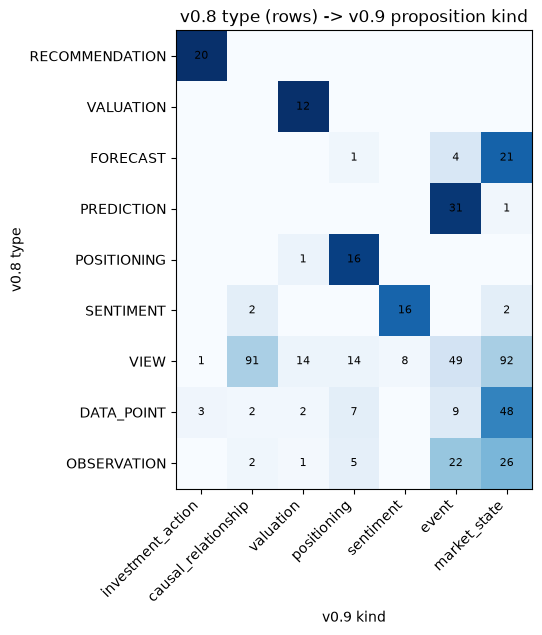

share
v08_type                                  
RECOMMENDATION RECOMMENDATION · ACT   0.90
               OBSERVATION · ACT      0.10
VALUATION      ASSESSMENT · VAL       1.00
FORECAST       PREDICTION · MS        0.81
               PREDICTION · EVT       0.15
               ASSESSMENT · POS       0.04
PREDICTION     PREDICTION · EVT       0.97
               PREDICTION · MS        0.03
POSITIONING    OBSERVATION · POS      0.88
               ASSESSMENT · POS       0.06
               ASSESSMENT · VAL       0.06
SENTIMENT      OBSERVATION · SENT     0.60
               ASSESSMENT · SENT      0.20
               ASSESSMENT · CAUSE     0.10
VIEW           ASSESSMENT · CAUSE     0.27
               ASSESSMENT · MS        0.17
               PREDICTION · MS        0.16
DATA_POINT     OBSERVATION · MS       0.68
               OBSERVATION · EVT      0.11
               OBSERVATION · POS      0.10
OBSERVATION    OBSERVATION · MS       0.46
               OBSERVATION · EVT      0.36
               OBSERVATION · POS      0.09

In [37]:
heatmap(
    pd.crosstab(matched["v08_type"], matched["proposition_kind"]).reindex(index=V08_TYPES, columns=KINDS, fill_value=0),
    "v0.8 type (rows) -> v0.9 proposition kind",
    "v0.9 kind",
    "v0.8 type",
)
plt.show()
# The three most common function · kind destinations of each v0.8 type.
destination = matched["claim_type"] + " · " + matched["kind"].fillna("?")
(
    destination.groupby(matched["v08_type"]).value_counts(normalize=True).round(2)
    .groupby(level=0).head(3).to_frame("share").reindex(V08_TYPES, level=0)
)

### Observations

523 of 618 v0.9 statements were matched to a v0.8 statement.

| v0.8 type | n | v0.9 destination |
|---|---|---|
| RECOMMENDATION | 20 | REC·ACT 90%, OBS·ACT 10% (trading-model holdings) |
| VALUATION | 12 | ASSESSMENT·VAL 100% |
| FORECAST | 26 | PREDICTION·MS 81%, PREDICTION·EVT 15% |
| PREDICTION | 32 | PREDICTION·EVT 97% |
| POSITIONING | 17 | OBSERVATION·POS 88% |
| SENTIMENT | 20 | OBSERVATION·SENT 60%, ASSESSMENT·SENT 20% |
| **VIEW** | **269** | ASSESSMENT 63%, PREDICTION 34%, OBSERVATION 3%. Kinds: CAUSE 34%, MS 34%, EVT 18% |
| DATA_POINT | 71 | OBSERVATION 96% (MS 68%) |
| OBSERVATION | 56 | OBSERVATION 91% (MS 46%, EVT 36%) |

- The specific v0.8 types map almost one-to-one. The old FORECAST vs PREDICTION split survives as the kind split (MS vs EVT), so no information is lost.
- **VIEW was 51% of matched statements.** v0.9 resolves it into a function (assessment or prediction) and a kind (mechanism, state or event).
- DATA_POINT and OBSERVATION merge into OBSERVATION. Numbers are now an attribute rather than a type (see §7).


## 6. Claim-function boundaries

- ASSESSMENT vs PREDICTION: vulnerability or bias alone is not a prediction; a committed future outcome is.
- ASSESSMENT vs OBSERVATION: a judgement is an assessment; a report, estimate or attributed state is an observation.
- RECOMMENDATION subtypes: trade, allocation, rating.

In [38]:
display(pd.crosstab(claims["claim_type"], claims["modality"], normalize="index").round(2).reindex(FUNCTIONS))
pd.crosstab(memberships["claim_type"], memberships["role"]).reindex(FUNCTIONS)

modality,ASSERTED,HEDGED,SPECULATIVE
claim_type,,,
RECOMMENDATION,1.00,0.00,0.00
PREDICTION,0.26,0.46,0.29
ASSESSMENT,0.66,0.28,0.06
OBSERVATION,1.00,0.00,0.00


role,catalysts,conditions,core_claim,qualifiers,rationale,risks,supporting
claim_type,,,,,,,
RECOMMENDATION,0,0,27,0,0,0,3
PREDICTION,2,18,66,25,0,10,107
ASSESSMENT,0,5,50,25,0,7,179
OBSERVATION,0,0,0,0,204,0,0


In [39]:
BOUNDARY_PROBES = {
    "future_marker": r"\b(?:will|would|expect\w*|forecast\w*|by (?:end|year-end|mid)|next (?:year|week|month|quarter))\b",
    "vulnerability": r"\b(?:vulnerab\w*|risks?|exposed|prone|bias|susceptible)\b",
    "judgement": r"\b(?:we think|we believe|in our view|suggests?|likely|appears?|seems?|looks?)\b",
    "author_voice": r"\b(?:we|our|the author)\b",
    "number": r"\d",
}
display(fill_rates(claims, BOUNDARY_PROBES).reindex(columns=FUNCTIONS))

is_future = probe(claims, {"f": BOUNDARY_PROBES["future_marker"]})["f"]
future_assessments = claims[(claims["claim_type"] == "ASSESSMENT") & is_future]
print(f"{len(future_assessments)} ASSESSMENT statements with a future marker (candidate missed predictions)")
future_assessments[SHOW].head(30)

claim_type,RECOMMENDATION,PREDICTION,ASSESSMENT,OBSERVATION
future_marker,0.00,0.59,0.15,0.12
vulnerability,0.04,0.04,0.25,0.04
judgement,0.00,0.15,0.11,0.00
author_voice,0.14,0.00,0.00,0.00
number,0.18,0.38,0.16,0.54


33 ASSESSMENT statements with a future marker (candidate missed predictions)


,label,model,statement_id,claim_type,kind,modality,attribution,statement
6,BC FX Views,opus,S007,ASSESSMENT,CAUSE,HEDGED,NaN,"The recent sharp JPY appreciation was likely driven by BoJ rate hike expectations, technical factors and FX supply-demand, including anticipation of pension..."
9,BC FX Views,opus,S010,ASSESSMENT,CAUSE,HEDGED,NaN,Further JPY appreciation may require a surprise relative to already hawkish BoJ expectations.
35,BC FX Views,opus,S036,ASSESSMENT,VAL,ASSERTED,NaN,Market pricing of BoJ hikes exceeds Barclays' forecast path.
40,BC FX Views,opus,S041,ASSESSMENT,CAUSE,HEDGED,NaN,Faster BoJ hike expectations have likely strengthened the JPY through both the rate differential channel and compression of the Takaichi policy risk premium...
45,BC FX Views,opus,S046,ASSESSMENT,CAUSE,ASSERTED,NaN,Avoiding a sharp increase in Fed rate hike expectations will be important for sustaining the JPY's appreciation bias.
47,BC FX Views,opus,S048,ASSESSMENT,EVT,ASSERTED,NaN,Whether the GPIF will actually decide to change its asset allocation remains unclear.
50,BC FX Views,opus,S051,ASSESSMENT,CAUSE,SPECULATIVE,NaN,Raising the GPIF's expected domestic bond return from the 1.5% average across its four scenarios to 1.8% could justify a 5-10pp reallocation from foreign bo...
52,BC FX Views,opus,S053,ASSESSMENT,POS,SPECULATIVE,NaN,"Given GPIF total assets of JPY320trn, a 5-10pp shift back to domestic assets would generate around JPY16-32trn of one-off JPY buying, comparable with this y..."
70,BC FX Views,opus,S071,ASSESSMENT,POS,HEDGED,NaN,The USDJPY undershoot likely reflects speculative positioning that may be prone to changes in expectations around the BoJ and GPIF.
76,BC FX Views,opus,S077,ASSESSMENT,CAUSE,ASSERTED,NaN,"Sustained medium- to long-term JPY appreciation would require structural changes such as rate-differential convergence through Fed cuts, a higher equity ris..."


In [40]:
is_judged = probe(claims, {"j": BOUNDARY_PROBES["judgement"]})["j"]
judged_observations = claims[(claims["claim_type"] == "OBSERVATION") & is_judged]
print(f"{len(judged_observations)} OBSERVATION statements with judgement wording")
display(judged_observations[SHOW].head(20))
is_vulnerable = probe(claims, {"v": BOUNDARY_PROBES["vulnerability"]})["v"]
vulnerable_predictions = claims[(claims["claim_type"] == "PREDICTION") & is_vulnerable]
print(f"{len(vulnerable_predictions)} PREDICTION statements with vulnerability or risk wording")
vulnerable_predictions[SHOW].head(20)

0 OBSERVATION statements with judgement wording


,label,model,statement_id,claim_type,kind,modality,attribution,statement


7 PREDICTION statements with vulnerability or risk wording


,label,model,statement_id,claim_type,kind,modality,attribution,statement
399,BofA Liquid Insight,haiku,S044,PREDICTION,CAUSE,ASSERTED,NaN,French downside risks to the EUR become more relevant for markets once there is greater clarity on the presidential field.
441,BofA Liquid Insight,opus,S042,PREDICTION,CAUSE,ASSERTED,NaN,France-related downside risks to the EUR will become more relevant for markets once there is greater clarity on the presidential field.
452,BofA Sept FOMC,haiku,S008,PREDICTION,MS,HEDGED,NaN,"If the Fed does not hike at current pricing, it risks a sharp and disorderly UST long-end move."
527,BofA Sept FOMC,opus,S020,PREDICTION,MS,HEDGED,NaN,"If Warsh adopts his Jackson Hole stance, risk assets will be challenged."
558,BofA Sept FOMC,opus,S051,PREDICTION,EVT,SPECULATIVE,NaN,"Warsh might point to the rise in oil as an upside risk to inflation, contradicting his prior stance that oil shocks are one-offs."
591,BofA Sept FOMC,opus,S084,PREDICTION,EVT,HEDGED,NaN,Trump will understand the risks of bond un-anchoring and its market implications.
592,BofA Sept FOMC,opus,S085,PREDICTION,CAUSE,ASSERTED,NaN,"A hawkish hike, through higher front-end rates and curve twist flattening, will challenge BofA's prior bias for lower UST belly rates."


In [41]:
REC_PROBES = {
    "trade": r"\b(?:long|short|buy|sell|enter|exit|hedge|position|call|put|spread)\b",
    "allocation": r"\b(?:overweight|underweight|neutral|allocation|allocate)\b",
    "rating": r"\b(?:upgrade|downgrade|rating|outperform|underperform)\b",
}
recs = claims[claims["claim_type"] == "RECOMMENDATION"]
display(fill_rates(recs, REC_PROBES, by="model"))
recs[SHOW]

model,haiku,opus
trade,0.62,0.73
allocation,0.38,0.33
rating,0.00,0.00


,label,model,statement_id,claim_type,kind,modality,attribution,statement
150,Beam yields up Scotty,haiku,S031,RECOMMENDATION,ACT,ASSERTED,NaN,Stay underweight the USD in the portfolio.
157,Beam yields up Scotty,haiku,S038,RECOMMENDATION,ACT,ASSERTED,NaN,Maintain a short USD versus EUR position.
162,Beam yields up Scotty,haiku,S043,RECOMMENDATION,ACT,ASSERTED,NaN,Sit short of dollars into the Jackson Hole gathering.
173,Beam yields up Scotty,haiku,S054,RECOMMENDATION,ACT,ASSERTED,NaN,Maintain a long CAD versus AUD position.
182,Beam yields up Scotty,haiku,S063,RECOMMENDATION,ACT,ASSERTED,NaN,Maintain a short GBP versus EUR position.
192,Beam yields up Scotty,haiku,S073,RECOMMENDATION,ACT,ASSERTED,NaN,Maintain a neutral NZD stance.
198,Beam yields up Scotty,haiku,S079,RECOMMENDATION,ACT,ASSERTED,NaN,Maintain a neutral SEK stance this week.
202,Beam yields up Scotty,haiku,S083,RECOMMENDATION,ACT,ASSERTED,NaN,Maintain a neutral NOK stance for now.
209,Beam yields up Scotty,haiku,S090,RECOMMENDATION,ACT,ASSERTED,NaN,Maintain a long JPY versus CHF position.
221,Beam yields up Scotty,haiku,S102,RECOMMENDATION,ACT,ASSERTED,The Machines,The Machines are short CHF versus JPY.


### Observations

- **The hard rules hold:**
  - OBSERVATION and RECOMMENDATION are 100% ASSERTED.
  - OBSERVATION appears only as `rationale` (204 of 204).
  - RECOMMENDATION is a `core_claim` 27 of 30 times.
- Hedging sits in PREDICTION (46% HEDGED, 29% SPECULATIVE). ASSESSMENT is 66% ASSERTED.
- **ASSESSMENT vs OBSERVATION:** no OBSERVATION contains judgement wording. The leaks go the other way: haiku labels short characterisations as OBSERVATION (see §4).
- **ASSESSMENT vs PREDICTION:** 33 assessments contain future wording, and most are not missed predictions:

| Pattern | Example | Verdict |
|---|---|---|
| Conditional mechanism | "Twist steepening would come from…", "reaction will depend on…" | ASSESSMENT·CAUSE is defensible |
| Necessary condition | "would require c.60bp of measures", "may require a surprise" | ASSESSMENT |
| Attributed expectation | "Investors expect a pickup in volatility" | Arguably OBSERVATION·SENT |
| Committed conditional outcome | haiku "Bond yields would be lower/higher…" (FOMC scenarios), "UST buybacks would be futile" | **Missed PREDICTION**: opus labels the same statements PREDICTION |

- Only 7 predictions contain risk or vulnerability wording, and all of them commit to an outcome ("risk assets will be challenged"), so this boundary works.
- **Recommendations** are trade 62–73% and allocation 33–38%, with no ratings (these FX/rates samples have none).
  - Only Beam and Liquid Insight contain recommendations.
  - Opus packs the entry, take-profit and stop levels into one statement; haiku states only the action.


## 7. Proposition kinds

- Numbers should now be attributes: quantitative content should appear across functions, mostly in PREDICTION and OBSERVATION.
- `causal_relationship` should carry causal wording; other kinds should not.
- Within PREDICTION, `event` (discrete occurrence) vs `market_state` (variable level or change).

In [42]:
QUANT_PROBES = {
    "number": r"\d",
    "percent_bp": r"\d\s?(?:%|bps?\b|pp\b)",
    "level_target": r"\b(?:to|at|towards|reach\w*|target\w*|around|near)\s+[$€£¥]?\d",
    "range": r"\d\s?(?:-|–|to)\s?\d",
    "horizon": (
        r"\b(?:by|in|through|until|over)\s+(?:the\s+)?(?:end|year-end|mid|early|late|next|Q\d|H\d|\d{4}"
        r"|january|february|march|april|may|june|july|august|september|october|november|december)"
    ),
}
display(fill_rates(claims, QUANT_PROBES).reindex(columns=FUNCTIONS))
fill_rates(claims[claims["claim_type"] == "PREDICTION"], QUANT_PROBES, by="proposition_kind")

claim_type,RECOMMENDATION,PREDICTION,ASSESSMENT,OBSERVATION
number,0.18,0.38,0.16,0.54
percent_bp,0.04,0.23,0.02,0.17
level_target,0.18,0.07,0.02,0.08
range,0.00,0.08,0.01,0.04
horizon,0.00,0.09,0.02,0.12


proposition_kind,causal_relationship,event,market_state,positioning,sentiment
number,0.18,0.32,0.46,0.14,1.00
percent_bp,0.06,0.11,0.37,0.00,0.67
level_target,0.00,0.03,0.13,0.00,0.00
range,0.00,0.03,0.15,0.00,0.00
horizon,0.00,0.10,0.10,0.14,0.00


In [43]:
CAUSAL = {
    "causal_wording": (
        r"\b(?:drive[sn]?|driven|support\w*|weigh\w*|because|due to|lead\w* to|push\w*|reflect\w*|caus\w*"
        r"|boost\w*|hurt\w*|explain\w*|on the back of|as a result|amid)\b"
    )
}
display(fill_rates(claims, CAUSAL, by="proposition_kind").reindex(columns=KINDS))
pred = claims[claims["claim_type"] == "PREDICTION"]
has_number = pred["statement"].str.contains(r"\d", na=False).rename("has_number")
display(pd.crosstab(pred["proposition_kind"], has_number))
print("PREDICTION · event with a number (sized events):")
pred[(pred["proposition_kind"] == "event") & has_number][SHOW].head(20)

proposition_kind,investment_action,causal_relationship,valuation,positioning,sentiment,event,market_state
causal_wording,0.18,0.25,0.06,0.14,0.07,0.04,0.1


has_number,False,True
proposition_kind,,
causal_relationship,14,3
event,48,23
market_state,44,38
positioning,6,1
sentiment,0,3


PREDICTION · event with a number (sized events):


,label,model,statement_id,claim_type,kind,modality,attribution,statement
34,BC FX Views,opus,S035,PREDICTION,EVT,ASSERTED,NaN,"Barclays forecasts BoJ hikes in September, January and July, taking the policy rate to 1.75%."
39,BC FX Views,opus,S040,PREDICTION,EVT,HEDGED,NaN,"BoJ signalling of hikes beyond 2% is unlikely, at least at this point."
222,Beam yields up Scotty,haiku,S103,PREDICTION,EVT,ASSERTED,NaN,The SNB will keep policy unchanged through all of 2026.
240,Beam yields up Scotty,opus,S009,PREDICTION,EVT,SPECULATIVE,NaN,The renewed US-Canada trade dispute could see more U-turns before meaningful trade sanctions are imposed on 1 January 2027.
257,Beam yields up Scotty,opus,S026,PREDICTION,EVT,HEDGED,NaN,The US Treasury is unlikely to accept $32bn worth of par in buyback offers.
338,Beam yields up Scotty,opus,S107,PREDICTION,EVT,ASSERTED,NaN,The SNB will leave policy unchanged through all of 2026.
359,BofA Liquid Insight,haiku,S004,PREDICTION,EVT,HEDGED,NaN,"The next major France-related catalyst for the EUR is more likely to be the presidential election, potentially in Q1 2027."
364,BofA Liquid Insight,haiku,S009,PREDICTION,EVT,ASSERTED,NaN,The government manages to present and pass a budget plan with sufficient corrective action to keep the planned deficit unchanged vs 2026.
367,BofA Liquid Insight,haiku,S012,PREDICTION,EVT,SPECULATIVE,NaN,"In a snap election scenario, the first round of parliamentary elections would have to follow within 2-4 weeks."
403,BofA Liquid Insight,opus,S004,PREDICTION,EVT,HEDGED,NaN,"The next major France-related catalyst for the EUR is more likely to be the presidential election, potentially in Q1 2027 as the candidate field becomes cle..."


In [44]:
# Two examples per kind and model.
claims.groupby(["proposition_kind", "model"]).head(2).sort_values(["proposition_kind", "model"])[SHOW]

,label,model,statement_id,claim_type,kind,modality,attribution,statement
128,Beam yields up Scotty,haiku,S009,ASSESSMENT,CAUSE,ASSERTED,NaN,Bessent's intervention has caused the market to focus on the yield curve and debt sustainability.
143,Beam yields up Scotty,haiku,S024,ASSESSMENT,CAUSE,ASSERTED,NaN,AI investment has led to a sharp increase in long-duration corporate debt issuance.
6,BC FX Views,opus,S007,ASSESSMENT,CAUSE,HEDGED,NaN,"The recent sharp JPY appreciation was likely driven by BoJ rate hike expectations, technical factors and FX supply-demand, including anticipation of pension..."
9,BC FX Views,opus,S010,ASSESSMENT,CAUSE,HEDGED,NaN,Further JPY appreciation may require a surprise relative to already hawkish BoJ expectations.
123,Beam yields up Scotty,haiku,S004,OBSERVATION,EVT,ASSERTED,NaN,Bessent announced an increase in the long-end Treasury buyback size from $2bn to $4bn.
127,Beam yields up Scotty,haiku,S008,ASSESSMENT,EVT,ASSERTED,NaN,Bessent has alerted the market to his concerns over rising yields.
34,BC FX Views,opus,S035,PREDICTION,EVT,ASSERTED,NaN,"Barclays forecasts BoJ hikes in September, January and July, taking the policy rate to 1.75%."
39,BC FX Views,opus,S040,PREDICTION,EVT,HEDGED,NaN,"BoJ signalling of hikes beyond 2% is unlikely, at least at this point."
150,Beam yields up Scotty,haiku,S031,RECOMMENDATION,ACT,ASSERTED,NaN,Stay underweight the USD in the portfolio.
157,Beam yields up Scotty,haiku,S038,RECOMMENDATION,ACT,ASSERTED,NaN,Maintain a short USD versus EUR position.


### Observations

- **Numbers are now attributes.** Share of statements containing a number: OBSERVATION 54%, PREDICTION 38%, RECOMMENDATION 18%, ASSESSMENT 16%.
- **Within PREDICTION, market_state carries levels and ranges** (%/bp 37%, range 15%, level 13%), while event carries fewer (%/bp 11%).
  - Sized decisions ("Fed will hike 25bp", "SNB on hold through 2026") are consistently labelled EVT.
- **causal_relationship is the weakest kind.**
  - The causal-wording probe hits only 25% of CAUSE statements, against at most 18% for other kinds.
  - Many CAUSE statements use other phrasing: "vulnerable to", "require", "depend on", "determined by".
  - It also has the lowest model agreement (0.78) and works as a catch-all for "X matters for Y".
- **event vs market_state for policy-path predictions** is unresolved. Dot plots, "total hikes" and terminal-rate predictions split between EVT and MS, which is why FOMC kind agreement is lowest (0.74).


## 8. Scenarios

In [45]:
rows = []
for path in sorted(RUNS_DIR.glob("*/*/argument_map.yaml")):
    map_ = load_argument_map(path)
    types = {s.id: s.claim_type for s in map_.statements}
    for scenario in map_.scenarios:
        rows.append({
            "label": LABEL.get(path.parent.parent.name, path.parent.parent.name),
            "model": path.parent.name,
            "id": scenario.id,
            "scenario": scenario.label,
            "role": scenario.role,
            "orientation": scenario.outcome_orientation,
            "purpose": scenario.purpose,
            "assumptions": ", ".join(types.get(s, "?") for s in scenario.assumptions),
            "outcomes": ", ".join(types.get(s, "?") for s in scenario.outcomes),
            "recommendations": len(scenario.recommendations),
        })
scenarios = pd.DataFrame(rows)
scenarios

,label,model,id,scenario,role,orientation,purpose,assumptions,outcomes,recommendations
0,BC FX Views,opus,SC001,GPIF 5-10pp reallocation to domestic bonds,unspecified,upside,sensitivity,ASSESSMENT,"ASSESSMENT, PREDICTION",0
1,BofA Liquid Insight,haiku,SC001,Snap parliamentary elections after presidential dissolution,unspecified,unspecified,unspecified,PREDICTION,PREDICTION,0
2,BofA Liquid Insight,opus,SC001,Post-presidential dissolution and snap parliamentary elections,unspecified,unspecified,unspecified,PREDICTION,"PREDICTION, ASSESSMENT",0
3,BofA Sept FOMC,haiku,SC001,Hawkish presser,baseline,mixed,forecast,PREDICTION,"PREDICTION, PREDICTION, ASSESSMENT, PREDICTION",0
4,BofA Sept FOMC,haiku,SC002,Dovish presser,alternative,mixed,sensitivity,PREDICTION,"PREDICTION, PREDICTION, ASSESSMENT, PREDICTION",0
5,BofA Sept FOMC,haiku,SC003,Fed hold,alternative,mixed,stress_test,ASSESSMENT,"PREDICTION, PREDICTION, PREDICTION, ASSESSMENT, PREDICTION",0
6,BofA Sept FOMC,opus,SC001,Fed hold,alternative,mixed,forecast,PREDICTION,"PREDICTION, PREDICTION, PREDICTION, PREDICTION, PREDICTION, PREDICTION, PREDICTION, PREDICTION, ASSESSMENT",0
7,BofA Sept FOMC,opus,SC002,Hawkish presser,baseline,mixed,forecast,PREDICTION,"PREDICTION, PREDICTION, PREDICTION, PREDICTION",0
8,BofA Sept FOMC,opus,SC003,Dovish presser,alternative,mixed,forecast,PREDICTION,"PREDICTION, PREDICTION, PREDICTION, PREDICTION",0
9,BofA Sept FOMC,opus,SC004,Bullish USD case,alternative,upside,forecast,PREDICTION,"PREDICTION, PREDICTION",0


In [46]:
in_scenario = claims.dropna(subset=["scenario_slots"]).assign(slot=lambda d: d["scenario_slots"].str.split("|"))
in_scenario = in_scenario.explode("slot")
in_scenario["scenario"] = in_scenario["slot"].str.split(":").str[0]
in_scenario["slot"] = in_scenario["slot"].str.split(":").str[1]
display(pd.crosstab(in_scenario["slot"], in_scenario["claim_type"]).reindex(columns=FUNCTIONS, fill_value=0))
in_scenario.sort_values(["label", "model", "scenario", "slot"])[
    ["label", "model", "scenario", "slot", "claim_type", "kind", "modality", "statement"]
]

claim_type,RECOMMENDATION,PREDICTION,ASSESSMENT,OBSERVATION
slot,,,,
assumptions,0,8,2,0
outcomes,0,31,6,0


,label,model,scenario,slot,claim_type,kind,modality,statement
50,BC FX Views,opus,SC001,assumptions,ASSESSMENT,CAUSE,SPECULATIVE,Raising the GPIF's expected domestic bond return from the 1.5% average across its four scenarios to 1.8% could justify a 5-10pp reallocation from foreign bo...
52,BC FX Views,opus,SC001,outcomes,ASSESSMENT,POS,SPECULATIVE,"Given GPIF total assets of JPY320trn, a 5-10pp shift back to domestic assets would generate around JPY16-32trn of one-off JPY buying, comparable with this y..."
53,BC FX Views,opus,SC001,outcomes,PREDICTION,CAUSE,HEDGED,"Because the GPIF would execute a reallocation with its market impact in mind, the effect on JPY appreciation would likely be much more limited than that of ..."
366,BofA Liquid Insight,haiku,SC001,assumptions,PREDICTION,EVT,SPECULATIVE,The next President could dissolve parliament and call for snap elections.
367,BofA Liquid Insight,haiku,SC001,outcomes,PREDICTION,EVT,SPECULATIVE,"In a snap election scenario, the first round of parliamentary elections would have to follow within 2-4 weeks."
416,BofA Liquid Insight,opus,SC001,assumptions,PREDICTION,EVT,SPECULATIVE,The next French President could dissolve parliament and call snap parliamentary elections.
406,BofA Liquid Insight,opus,SC001,outcomes,ASSESSMENT,CAUSE,ASSERTED,Parliamentary fragmentation risks after a potential 2027 French snap parliamentary election following the presidential election are one of BofA's main mediu...
417,BofA Liquid Insight,opus,SC001,outcomes,PREDICTION,EVT,SPECULATIVE,"If the next French President dissolves parliament, the first round of parliamentary elections would have to follow within 2-4 weeks."
487,BofA Sept FOMC,haiku,SC001,assumptions,PREDICTION,MS,HEDGED,"If Warsh sounds inflation impatient, market likely raises hike peak and pulls forward timing."
486,BofA Sept FOMC,haiku,SC001,outcomes,PREDICTION,MS,HEDGED,"In a hawkish presser, 2Y yields would rise 5-10bp and 30Y yields would fall 5-10bp."


### Observations

| Sample | haiku | opus |
|---|---|---|
| BC FX | — (no valid map) | GPIF reallocation (upside, sensitivity) |
| Liquid Insight | Snap election (all `unspecified`) | Snap election (all `unspecified`) |
| FOMC | Hawkish presser (baseline), Dovish presser, Fed hold | Fed hold, Hawkish presser (baseline), Dovish presser, **Bullish USD** |

- **Both models find the same scenarios.** The 3 FOMC cases and the France case match; opus adds one extra FOMC case.
- **Slots:** assumptions hold 8 PREDICTION and 2 ASSESSMENT statements; outcomes hold 31 PREDICTION and 6 ASSESSMENT. **No scenario contains a recommendation**, because none of these notes conditions a trade on a scenario.
- **The models structure scenarios differently:**
  - Opus states each assumption as a bare condition (PREDICTION·EVT, SPECULATIVE) and gives each outcome atomically, one per yield move.
  - Haiku sometimes folds the outcome into the assumption ("If Warsh sounds impatient, market likely raises…"), and labels mechanism outcomes ASSESSMENT·CAUSE.
- **The settings carry little information beyond `role`:**
  - Orientation is almost always `mixed`.
  - Purpose varies by model: Fed hold is `stress_test` for haiku and `forecast` for opus.
  - Every setting on Liquid Insight is `unspecified`.


## 9. Attribution

In [47]:
attributed = claims.dropna(subset=["attribution"])
print(f"{len(attributed)} of {len(claims)} statements attributed to someone other than the author")
display(pd.crosstab(attributed["claim_type"], attributed["model"]).reindex(index=FUNCTIONS, columns=MODELS, fill_value=0))
display(attributed["attribution"].value_counts().head(20).to_frame("statements"))
attributed[SHOW].head(30)

46 of 618 statements attributed to someone other than the author


model,haiku,opus
claim_type,,
RECOMMENDATION,4,5
PREDICTION,0,0
ASSESSMENT,0,0
OBSERVATION,14,23


,statements
attribution,
BofA FX & Rates sentiment survey,6
rates market,5
Boost,4
Forest,3
Boost model,3
Forest model,3
MoF,2
CBO,2
The Machines,2


,label,model,statement_id,claim_type,kind,modality,attribution,statement
33,BC FX Views,opus,S034,OBSERVATION,MS,ASSERTED,OIS market,"The OIS market prices almost quarterly BoJ rate hikes, taking the policy rate to nearly 1.9% by July next year."
38,BC FX Views,opus,S039,OBSERVATION,MS,ASSERTED,BoJ,The currently priced 2% policy rate is already the central point of the BoJ's neutral rate estimates.
42,BC FX Views,opus,S043,OBSERVATION,EVT,ASSERTED,"Minister of Health, Labor and Welfare Ueno","Minister of Health, Labor and Welfare Ueno told reporters on 8 September that the investment environment has not deviated significantly from benchmark portf..."
104,BC FX Views,opus,S105,OBSERVATION,EVT,ASSERTED,MoF,"The MoF reported a JPY15.4trn JPY-buying/USD-selling intervention at end-July, the largest monthly total on record."
115,BC FX Views,opus,S116,OBSERVATION,EVT,ASSERTED,US Treasury Secretary Bessent,"In a 31 August CNBC interview, Treasury Secretary Bessent said he believes the Japanese government and the BoJ will do the things that lead to a stronger yen."
118,BC FX Views,opus,S119,OBSERVATION,EVT,ASSERTED,MoF,"The MoF said on 3 August that it plans to use the FIMA Repo Facility, which would let it raise intervention funds without selling US Treasury holdings."
141,Beam yields up Scotty,haiku,S022,OBSERVATION,MS,ASSERTED,CBO,The CBO projects net interest payments will top $2tr by 2035 (4.5% of GDP).
145,Beam yields up Scotty,haiku,S026,OBSERVATION,EVT,ASSERTED,Bessent,Bessent argued that corporates should be issuing more debt in the 3-7yr belly.
220,Beam yields up Scotty,haiku,S101,OBSERVATION,ACT,ASSERTED,The Machines,Five of the Machine's six picks use CHF as the funder.
221,Beam yields up Scotty,haiku,S102,RECOMMENDATION,ACT,ASSERTED,The Machines,The Machines are short CHF versus JPY.


### Observations

- 46 of 618 statements (7%) are attributed. **All of them are OBSERVATION (37) or RECOMMENDATION (9).** Third-party views are reported, never adopted as PREDICTION or ASSESSMENT.
- In-house forecasts ("Barclays forecasts…", "BofA US Economics forecasts…") stay unattributed PREDICTIONs, as intended.

| Source group | Statements | Name variants |
|---|---|---|
| Trading models (State Street Boost, Forest) | ~19 | 8: Boost, Boost model, Forest, Forest model, The Machines, State Street Machines (+3 bracketed forms) |
| Market pricing | 8 | 4: rates market, rate markets, OIS market, market |
| Surveys / in-house desks | 8 | BofA FX & Rates sentiment survey, BofA European equity strategists |
| Officials / institutions | 8 | MoF, BoJ, CBO, Bessent / US Treasury Secretary Bessent, Ueno |

- **Names are not normalised.** One model family appears under 8 strings, and the same official appears with and without his title.
- **Trading-model content is split within a single map:** holdings and picks are RECOMMENDATION (haiku 3, opus 4), while funding and drivers are OBSERVATION·ACT or OBSERVATION·CAUSE.


## 10. Summary

7 valid maps from 4 samples. BC FX is opus-only.

| Question | Answer |
|---|---|
| 1. Model invariance | **Yes.** Function agreement is 0.91–0.96, against 0.84–0.86 for the v0.8 types. Kind agreement is 0.74–0.93; function and kind together, 0.72–0.90. |
| 2. Where the v0.8 types went | Near one-to-one for VALUATION, FORECAST, PREDICTION, POSITIONING and DATA_POINT. The VIEW catch-all (51% of matched statements) splits into ASSESSMENT (63%) and PREDICTION (34%). |
| 3. Function boundaries | The hard rules hold. Two soft spots: short characterisations (ASSESSMENT vs OBSERVATION), and committed conditional outcomes that haiku labels ASSESSMENT·CAUSE. |
| 4. Proposition kinds | Numbers are now an attribute. causal_relationship is the least stable kind (0.78). event vs market_state is ambiguous for policy-path predictions. |
| 5. Scenarios and attribution | Both models find the same scenarios, but none contains a recommendation and the settings carry little information. Attribution appears only on OBSERVATION and RECOMMENDATION, and source names are not normalised. |

**Open decisions** (the suggested rule is in italics)

| # | Topic | Options |
|---|---|---|
| 1 | Haiku on BC FX | Accept opus-only (current) **or** repair evidence before validation: snap near-verbatim quotes to the source and drop cues that are not in the evidence |
| 2 | Attribution names | Free text **or** a source registry: `source_id` plus a type (market_pricing / model / official / survey / in_house) |
| 3 | Trading-model picks | *Picks and holdings → RECOMMENDATION + attribution; model features and drivers → OBSERVATION* **or** everything OBSERVATION·ACT |
| 4 | Policy-path predictions | *A decision at a dated meeting → EVT; a projected level, path or cumulative amount (dots, total hikes, terminal rate) → MS* |
| 5 | Conditional mechanisms | *Committed directional outcome ("X would push yields higher") → PREDICTION·CAUSE; dependency or requirement ("Y depends on / requires X") → ASSESSMENT·CAUSE* |
| 6 | Characterisations | *Evaluative description with no source or measure ("most dovish", "risk appetite positive") → ASSESSMENT* |
| 7 | Scenario settings | Keep `role`; drop or demote `outcome_orientation` and `purpose` |

**Next:** update `taxonomy_v09.yaml` with the decisions above, then run the remaining 16 samples (about $26 for opus) once approved. Applying the rule changes first avoids paying twice.
